## **Exploratory Data Analysis on Student Dataset**

#### **Dataset Schema**

> **University**(Student_ID, Full_Name, Application_Date, Date_of_Birth, Age, Department, Country, Email, Fee_Paid, GPA, Attendance_Percentage, Is_Active,Enrollment_Status)

We have three distinct types of features to analyze:

- **Numerical**: `Age`, `Fee_Paid`, `GPA`, `Attendance_Percentage`

- **Categorical**: `Department`, `Country`, `Is_Active`, `Enrollment_Status`

- **Temporal**: `Application_Date`, `Date_of_Birth`

- **Identifiers/Text**: `Student_ID`, `Full_Name`, `Email`.



#### **Let's Ingest the Dataset**

In [2]:
import pandas as pd
import numpy as np
import os

from pathlib import Path
# Finished importing required modules.

# The Base Directory
BASE_DIR: str = '../../Data_Cleaning_and_Preprocessing/cleaned_data_sets/Production/'
# File path.
file_path: str = f'{BASE_DIR}/Production_University_Data_v1.parquet'

def load_production_data(file_path: Path | str) -> pd.DataFrame:
    """Safely loads a Parquet file with built-in validation."""

    # 1. Convert string to Path object if necessary
    path_obj = Path(file_path)

    # 2. Defensinve Check: Does the file actually exist?
    if not path_obj.exists():
        raise FileNotFoundError(f'[CRITICAL ERROR] The data file is missing: {path_obj.resolve()}')

    try:
        # 3. The Actual Load
        print(f'Loading data from {path_obj.name}...')
        df = pd.read_parquet(path_obj)

        print(f'[SUCCESS] Successfully loaded {len(df)} rows.')
        return df
    except Exception as e:
        print(f'[CRITICAL ERROR] Failed to read the Parquet file. It may be corrupted. Details: {e}')
        raise # re-raise the error because the pipeline cannot continue without data

uni_df: pd.DataFrame = load_production_data(file_path=file_path)

Loading data from Production_University_Data_v1.parquet...
[SUCCESS] Successfully loaded 915 rows.


In [3]:
uni_df.head()

,STUDENT_ID,FULL_NAME,APPLICATION_DATE,DATE_OF_BIRTH,AGE,DEPARTMENT,COUNTRY,EMAIL,FEE_PAID,GPA,ATTENDANCE_PERCENTAGE,IS_ACTIVE,LAB_SENSOR_RPM,ENROLLMENT_STATUS
0,STU00114,Farhan Farooqi,2022-04-16,1980-04-25,44,data science,India,farhan.farooqi114@gmail.com,3579.9300,2.91,70.3,False,4289.05,unknown
1,STU00793,Riya Rana,2021-07-08,2002-12-13,21,finance,India,riya.rana793@yahoo.com,0.0000,2.88,41.4,True,1430.70,Graduated
2,STU00741,Karan Kapoor,2021-06-06,1989-06-21,34,electrical engineering,Pakistan,karan.kapoor741@outlook.com,4843.1500,2.34,90.1,True,1093.00,Enrolled
3,STU00432,Ava Siddiqui,2024-04-03,2004-03-31,20,data science,USA,ava.siddiqui432@yahoo.com,2488.4800,1.86,84.9,False,4289.05,Withdrawn
4,STU00243,Anjali Young,2024-03-16,1989-09-22,34,business administration,UAE,anjali.young243@outlook.com,0.4503,3.53,64.0,False,2536.60,Withdrawn


**A Corruption , found it the dataset, I guess the cleaning process didn't go much well....**

The Age and Date_of_Birth doesn't match properly let's fix it first.....

- **HOW**: let's create a new column containing the correct date of birth and age combination. Flag the wrong one , and fix them.

**NOTE**: There's Catch on the fixing via this approach...for those whose birthday isn't come yet in 2026, they might be calculated as few months older, however we'll fix that later.


In [4]:
curr_year: int = 2026 # current year

# The new Correct Age column.
uni_df['CORRECT_AGE'] = curr_year - uni_df['DATE_OF_BIRTH'].dt.year

# let's flag the curropted age columns.
flag_mask = uni_df['AGE'] != uni_df['CORRECT_AGE']

# uni_df[flag_mask].shape # 866 rows are corrupted....massive.

uni_df.loc[flag_mask,'AGE'] = uni_df['CORRECT_AGE']

uni_df.head()

,STUDENT_ID,FULL_NAME,APPLICATION_DATE,DATE_OF_BIRTH,AGE,DEPARTMENT,COUNTRY,EMAIL,FEE_PAID,GPA,ATTENDANCE_PERCENTAGE,IS_ACTIVE,LAB_SENSOR_RPM,ENROLLMENT_STATUS,CORRECT_AGE
0,STU00114,Farhan Farooqi,2022-04-16,1980-04-25,46,data science,India,farhan.farooqi114@gmail.com,3579.9300,2.91,70.3,False,4289.05,unknown,46
1,STU00793,Riya Rana,2021-07-08,2002-12-13,24,finance,India,riya.rana793@yahoo.com,0.0000,2.88,41.4,True,1430.70,Graduated,24
2,STU00741,Karan Kapoor,2021-06-06,1989-06-21,37,electrical engineering,Pakistan,karan.kapoor741@outlook.com,4843.1500,2.34,90.1,True,1093.00,Enrolled,37
3,STU00432,Ava Siddiqui,2024-04-03,2004-03-31,22,data science,USA,ava.siddiqui432@yahoo.com,2488.4800,1.86,84.9,False,4289.05,Withdrawn,22
4,STU00243,Anjali Young,2024-03-16,1989-09-22,37,business administration,UAE,anjali.young243@outlook.com,0.4503,3.53,64.0,False,2536.60,Withdrawn,37


In [5]:
# let's drop the exatra Correct Age column.
uni_df = uni_df.drop(columns='CORRECT_AGE')

# the lab sensor column is also useless in this particular dataset.
uni_df = uni_df.drop(columns='LAB_SENSOR_RPM')

**Since we fix a kind of Data Inconsistency**

Let's move on to our Univariate Analysis....

#### **1. Univariate Analysis**

Before comparing variables, we must first analze them into isolation, this is basically for getting hold with the shape of dataset.

- **Numerical Data**: We find out the central tendency (mean, median) and dispersion (standard deviation, variance) we look for outliers and skewness via ploting Histograms and boxplot.

- **Categorical Data**: we analyze frequency distribution. let's take an example we'll find out most of our students are from which country... we will use Bar chart for it.

### **Beginner Questions: (Univariate Analysis & Simple Distributions)**

These questions focus on understanding the shape and central tendency of one variable at a time.

1. What is the total number of records (students) in the dataset?

2. What is the overall average, median, minimum, and maximum `GPA`?

3. How are students distributed across different `Departments`?

4. Which `Country` has the highest number of students?

5. What is the average `AGE` of the student population?

6. What is the exact count and percentage of students markded as `Is_Active` (True vs. False)?

7. How many students fall into each category of `Enrollment_Status`?

8. What is the overall average `Attendance_Percentage`?

9. What is the distribution of `Fee_Paid` (are there are many zero-fee students or a standard flat rate)?

10. Are there any visible outliers in the `GPA` distribution (e.g., above 4.0 or exactly 0.0)?

In [6]:
# let's import the visualization libarary first.
import matplotlib.pyplot as plt

#### **Q1. What is the total number of records (students) in the dataset?**

In [7]:
print(f'The dataset contains the total of {len(uni_df)} records.')

The dataset contains the total of 915 records.


#### **Q2. What is the overall average, median, minimum, and maximum 'GPA`?**

In [8]:
uni_df['GPA'].describe()

count    915.000000
mean       2.822667
std        0.737827
min        1.500000
25%        2.155000
50%        2.880000
75%        3.470000
max        4.000000
Name: GPA, dtype: float64

#### **Q3. How are students distributed across different Departments?**

In [9]:
dept_counts = uni_df['DEPARTMENT'].value_counts()

dept_counts

DEPARTMENT
entrepreneurship           159
computer science           151
data science               146
finance                    127
mechanical engineering     121
electrical engineering     120
business administration     91
Name: count, dtype: int64

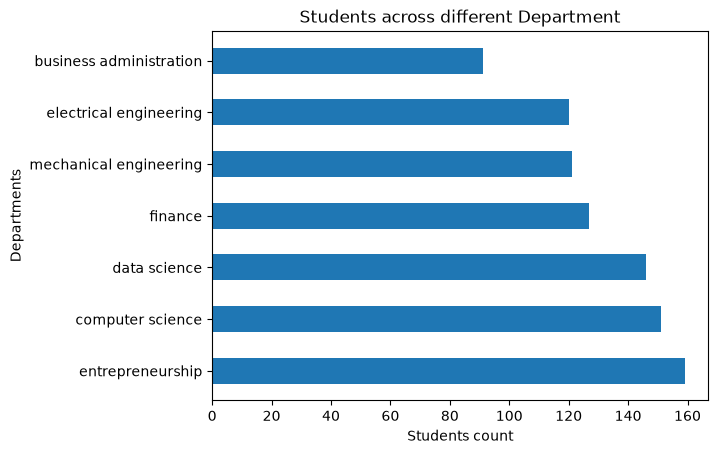

In [10]:
# Visualaization via matplotlib:

fig, ax = plt.subplots()

ax.barh(
    dept_counts.index,
    dept_counts.values,
    0.5,
)

ax.set_title('Students across different Department')
ax.set_xlabel('Students count')
ax.set_ylabel('Departments')

plt.show()

#### **Q4. Which `Country` has the highest number of students?**

In [11]:
student_count_via_country = uni_df['COUNTRY'].value_counts().sort_values(ascending=True) # India has the highest number students.
student_count_via_country

COUNTRY
Canada           78
UK               79
Germany          80
Saudi Arabia     89
Australia        90
Pakistan         94
UAE              96
Bangladesh       97
USA             105
India           107
Name: count, dtype: int64

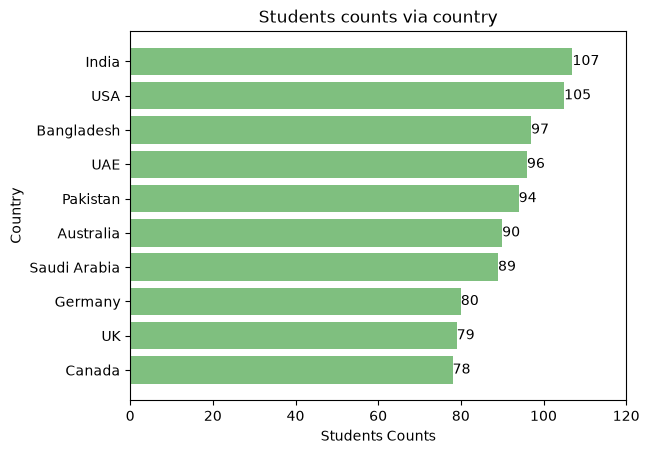

In [12]:
# Plot this too via matplotlib.

fig, ax = plt.subplots()

bar = ax.barh(
    student_count_via_country.index,
    student_count_via_country.values,
    alpha=0.5,
    color='green',
    height=0.8
)

ax.set_title('Students counts via country')
ax.set_xlabel('Students Counts')
ax.set_ylabel('Country')

ax.set_xlim(0, 120) # For shortning the lenght of the bar via increasing the range of x-axis.
ax.bar_label(bar)
plt.show()

#### **Q5. What is the average `AGE` of the student population?**

Mean: 34 AND Median: 34
The average age is 34.


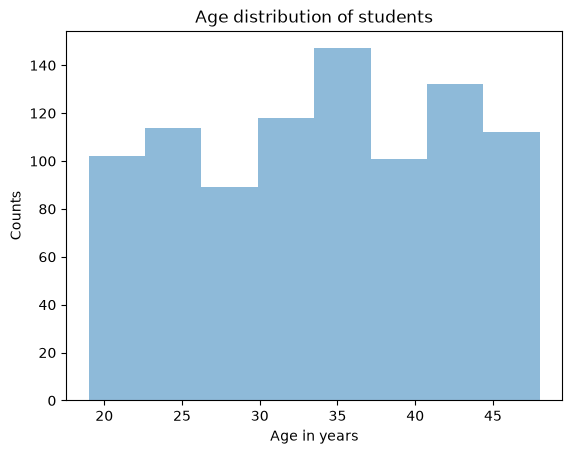

In [13]:
# let's see the distribution
mean_age: int= round(float(uni_df['AGE'].mean()))

median_age: int = int(uni_df['AGE'].median())

print(f'Mean: {mean_age} AND Median: {median_age}')

print(f'The average age is {mean_age}.')

import matplotlib.pyplot as plt

fig, ax = plt.subplots()

ax.hist(
    uni_df['AGE'],
    bins=8,
    alpha=0.5
)

ax.set_title('Age distribution of students')
ax.set_xlabel('Age in years')
ax.set_ylabel('Counts')

plt.show()

#### **Q6. What is the exact count and percentage of students markded as `IS_ACTIVE` (True vs False)?**

In [35]:
is_active_series = uni_df['IS_ACTIVE'].value_counts()
is_active_series[False]
# we have 
false_count = is_active_series[False]
true_count = is_active_series[True]

print(f"Exact count: False -> {false_count} AND True -> {true_count}")

false_per: float = 100 / len(uni_df) * false_count
true_per: float = 100 / len(uni_df) * true_count

print(f'{round(false_per, 2)} percentage of students are Not Active')
print(f'{round(true_per, 2)} percentage of students are Active.')

Exact count: False -> 518 AND True -> 397
56.61 percentage of students are Not Active
43.39 percentage of students are Active.


#### **Q7. How many students fall into each category of `Enrollment_Status`?**

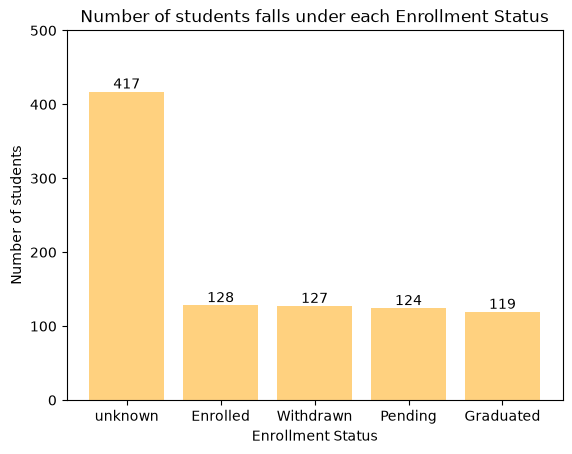

In [ ]:
enrollment_status = uni_df['ENROLLMENT_STATUS'].value_counts()

# let's visualize that via bar chart.
fig, ax = plt.subplots()

bar = ax.bar(
    enrollment_status.index,
    enrollment_status.values,
    alpha=0.5,
    color='orange',
)

ax.set_title('Number of students falls under each Enrollment Status')
ax.set_xlabel('Enrollment Status')
ax.set_ylabel('Number of students')

ax.set_ylim(0, 500)
ax.bar_label(bar)

plt.show()

#### **Q8. What is the overall average `Attendance_Percentage`?**

In [ ]:
mean_att_per: float = round(float(uni_df['ATTENDANCE_PERCENTAGE'].mean()), 2)

median_att_per: float = uni_df['ATTENDANCE_PERCENTAGE'].median()

# mean of Attendance percentage.
print(f'Mean: {mean_att_per} AND Median: {median_att_per}')
print(f'Hence, the overall average of Attendance Percentage is {mean_att_per}')

Mean: 70.15 AND Median: 70.3
Hence, the overall average of Attendance Percentage is 70.15


#### **Q9. What is the distribution of `FEE_PAID` (are there many zero-fee stundents or a standard flat rate)?**

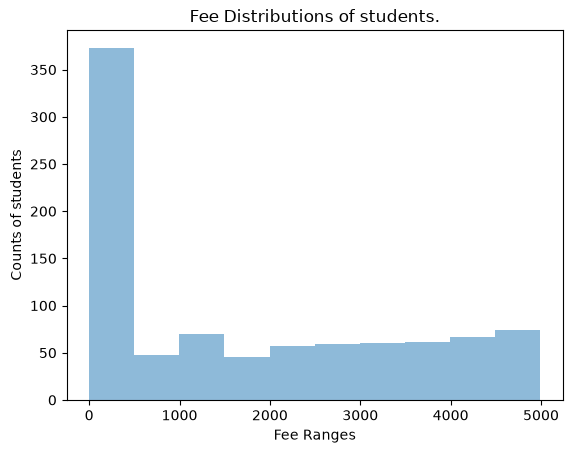

In [ ]:
# for distribution let's plot a histogram.
fig, ax = plt.subplots()

ax.hist(
    uni_df['FEE_PAID'],
    bins = 10,
    alpha=0.5
)

ax.set_title("Fee Distributions of students.")
ax.set_xlabel('Fee Ranges')
ax.set_ylabel('Counts of students')

plt.show()

# Absolutely there are many zero-fee studnets

#### **Q10. Are there any visible outliers in the `GPA` distribution (e.g., above 4.0 or exactly 0.0)?**

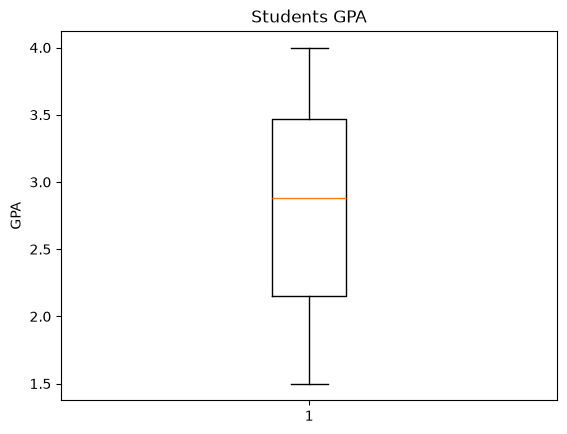

In [ ]:
# let's see this via ploting a box plot, much more efficient for determining the outliers.

fig, ax = plt.subplots()

ax.boxplot(
    uni_df['GPA']
)

ax.set_title('Students GPA')
ax.set_ylabel('GPA')

plt.show()

# Conclusion:

# No, there isn't any visible outlires in the GPA, the minimum  I guess 1.5 
# and the maximum is 4.0

### **Intermediate Questions: (Bivariate Analysis & Relationships)**

11. How does the average `GPA` vary across different `Departments`?

12. Is there a mathematical correlation between `Attendance_Percentage` and `GPA`?

13. Do students currently marked as `Is_Active` have a higher average `GPA` than inactive students?

14. Which `Country` contributes the highest total `Fee_Paid` to the university?

15. How does the average `AGE` differ based on a students's `Enrollment_Status`?

16. Is there an observable relationship between a student's `AGE` and their `GPA`?

17. How does the average `Fee_paid` compare across different `Departments`?

18. What is the trend of applications over time (grouping `Application_Date` by month or years)?

19. Does `Attendance_Perentage` vary significantly between students from different `Countries`?

20. Is there a difference in average `Fee_Paid` between active and inactive students?

#### **Q11. How does the average `GPA` vary across different `Departments`?**

In [ ]:
# Let's groupby on Departments first.
dept_av_gpa = uni_df.groupby('DEPARTMENT')['GPA'].mean().round(2).sort_values(ascending=True)
dept_av_gpa

DEPARTMENT
data science               2.72
electrical engineering     2.77
finance                    2.81
entrepreneurship           2.82
business administration    2.85
mechanical engineering     2.88
computer science           2.92
Name: GPA, dtype: float64

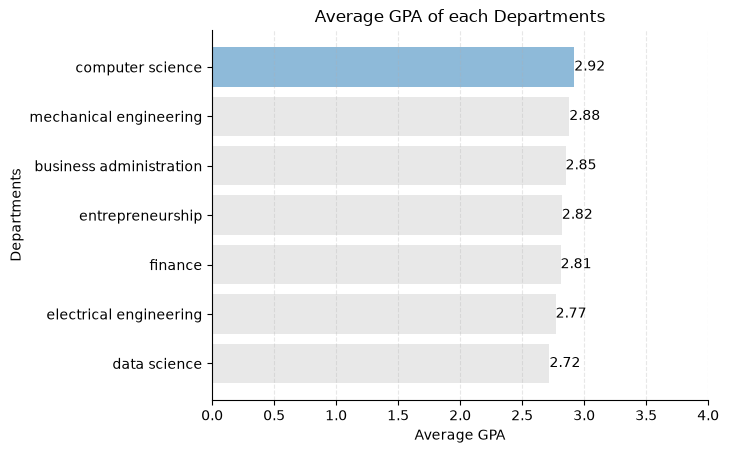

In [ ]:
# let's plot it in bar chart, I think would be the most appropriate for it
# bar chart is specifically used to compare different categories values.

# Creating a list of gray colors for all bars
colors: list = ['#d3d3d3'] * len(dept_av_gpa)
# Change the last bar (the highest GPA) to a bold color
colors[-1] = '#1f77b4'
fig, ax = plt.subplots()

bar = ax.barh(
    dept_av_gpa.index,
    dept_av_gpa.values,
    alpha=0.5,
    color= colors
)

ax.set_title('Average GPA of each Departments')
ax.set_xlabel('Average GPA')
ax.set_ylabel('Departments')

ax.bar_label(bar)
ax.set_xlim(0.0, 4.0)

# Remove the spines: the solid black box around the chart traps the data.
# we can turn off the top and right borders using:
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Faint Gridlines: Adding a faint vertical grid behind the bars
ax.grid(axis='x', linestyle='--', alpha=0.3)
plt.show()

#### **Q12. Is there a methematical correlations between `Attendance_Percentage` and `GPA`?**

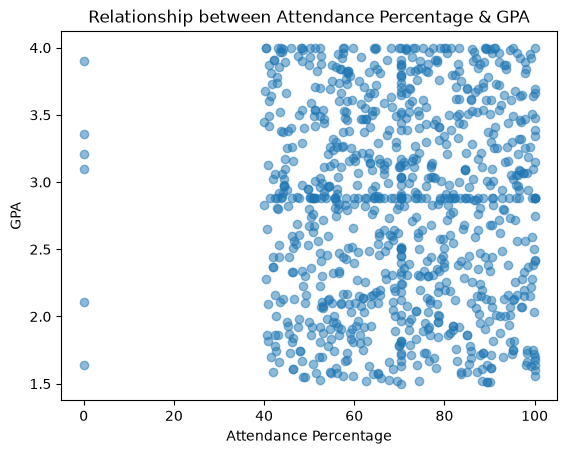

In [15]:
# The correlation , let's see....
# For that we'll gonna plot a scatterplot. to see any relation ship between
# Attendance Percentage and GPA.

fig, ax = plt.subplots()

ax.scatter(
    uni_df['ATTENDANCE_PERCENTAGE'],
    uni_df['GPA'],
    alpha=0.5
)

ax.set_title('Relationship between Attendance Percentage & GPA')
ax.set_xlabel('Attendance Percentage')
ax.set_ylabel('GPA')

plt.show()

#### **Let's see it in seaborn**

The relationship here is chaotic....it's showing that:

- the range of attendance percentage from 40 to 100, less attendance percent doesn't effecting on GPAs, even the 40 % attendance could score perfectly 4 GPA and even the 100 % attendance could score around 1.8 GPA.

- Notice the top left dot line tells, even those who have 0% attendance can score 1.5 to 4.0 GPA , The (Ghost students).

- The thick mid line of dots spliting the chart into half, are those students which have Null as GPA but we use average GPA to fill them, on our data cleaning process.

Let's go and plot it in seaborn.

### **Professional Upgrades for Dense Data**

When we ahve thousands of data points, a standard scatter plot suffer from **overplotting** (dots stacking on top of each other), which hides true density. while our use of `alpha=0.5` was a smart move, industry analysts rely on Seaborn for these specific scenarios.

#### **The "Prove It" Chart (Seaborn Regplot)**

If a stakeholder asks, "Is there a correlation?", a regression plot mathematically calculates the trend and draws a line through the data. If the line is flat, there is zero correlation.

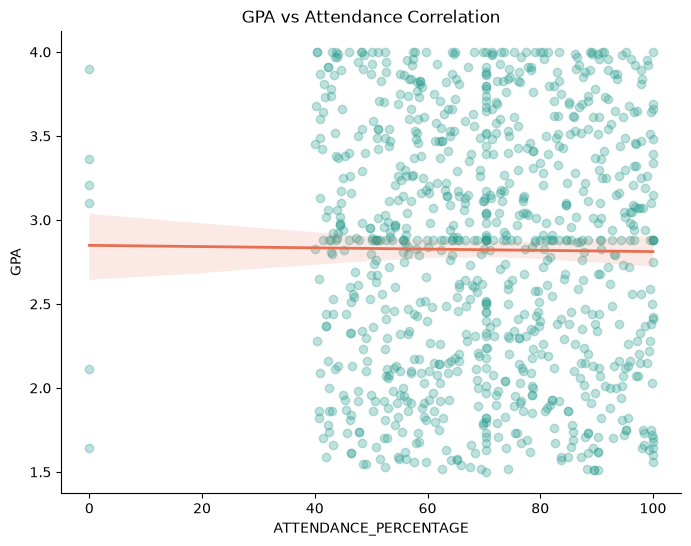

In [17]:
import seaborn as sns

fig, ax = plt.subplots(figsize=(8, 6))

# regplot adds a linear regression trndline
sns.regplot(
    data=uni_df,
    x= 'ATTENDANCE_PERCENTAGE',
    y='GPA',
    scatter_kws={'alpha' : 0.3, 'color': '#2a9d8f'}, # Teal dots
    line_kws={'color': '#e76f51', 'linewidth': 2} # Bold orange trendline
)

ax.set_title('GPA vs Attendance Correlation')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.show()

#### **Q13: Do students currently marked as `Is_Active` have a higher average `GPA` than inactive students?**

In [23]:
# let's group our data by IS_ACTIVE attribute:
av_gpa_by_activeness = uni_df.groupby('IS_ACTIVE')['GPA'].mean().round(3)
av_gpa_by_activeness

IS_ACTIVE
False    2.823
True     2.823
Name: GPA, dtype: float64

Well I guess Both active and not active categories of students have average GPAs same....we'll it's a massive red flag for a real world dataset, since this dataset is totally generated...let's move on to the next question.

#### **Q14: Which `Country` contributes the highest total `FEE_PAID` to the university?**

In [47]:
# let's group the data by country wise, then sum the total fee paid.

# total fee paid via each country.
total_fee_paid = uni_df.groupby('COUNTRY')['FEE_PAID'].sum().round(2).sort_values(ascending=True)
# And I have to round it since, the data isn't properly cleaned on the previous steps.

**Let's visualize it, I think bar plot would be the appropriate**

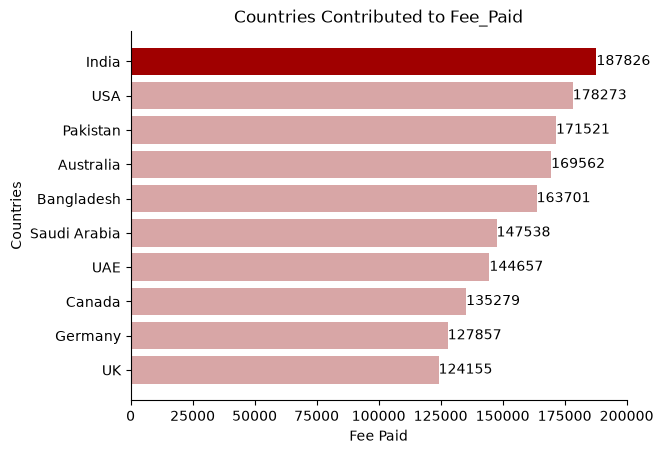

In [49]:
import matplotlib.ticker as ticker
# let's give every bar a color of light red (#d8a6a6)
colors: list = ['#d8a6a6'] * len(total_fee_paid)
# change the max value color to dark red (#a00000)
colors[-1] = '#a00000'
fig, ax = plt.subplots()

bar = ax.barh(
    total_fee_paid.index,
    total_fee_paid.values,
    color= colors,
    # alpha= 0.5,
)

ax.set_title('Countries Contributed to Fee_Paid')
ax.set_xlabel('Fee Paid')
ax.set_ylabel('Countries')

ax.bar_label(bar)

ax.set_xlim(0, 200000)
# Remove the spines:
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.show()

#### **Q15: How does the average `AGE` differ based on student's `Enrollment_Status`?**

In [57]:
# Let's group the datafram by it's Enrollement Status and calculate average Age
# of each group.

avg_age = uni_df.groupby('ENROLLMENT_STATUS')['AGE'].mean().round().astype('Int64')
avg_age

ENROLLMENT_STATUS
Enrolled     34
Graduated    35
Pending      34
Withdrawn    33
unknown      34
Name: AGE, dtype: Int64

In [58]:
median_age = uni_df.groupby('ENROLLMENT_STATUS')['AGE'].median()
median_age

ENROLLMENT_STATUS
Enrolled     33.0
Graduated    36.0
Pending      34.5
Withdrawn    34.0
unknown      35.0
Name: AGE, dtype: float64

As we build our intuition for data behavior, take a step back and look at the business logic here. The average age for a newly 'Enrolled' student is 34, and the average age for a 'Graduated' Student is 35.

In a real-world university dataset, the gap between enrollment and graduation is typically 3 to 4 years. The fact that all five categories are completely flat, hovering between 33 and 35, is yet another massive fingerprint of synthetically generated data.

#### **Q16: Is there an observable relationship between a student's `AGE` and their `GPA`?**

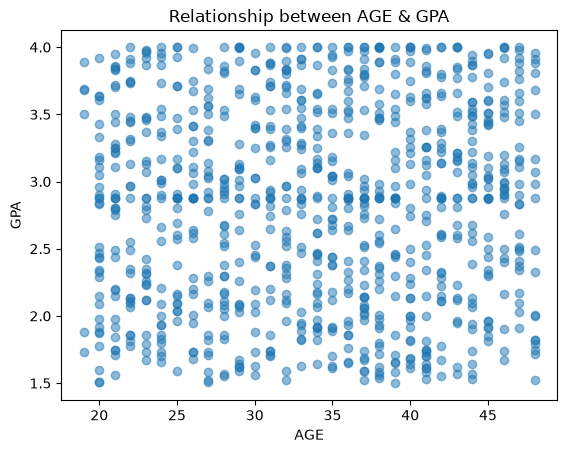

In [59]:
# let's see via ploting a scatter plot to see the relationship between AGE and GPA.
fig, ax = plt.subplots()

ax.scatter(
    uni_df['AGE'],
    uni_df['GPA'],
    alpha=0.5
)

ax.set_title('Relationship between AGE & GPA')
ax.set_xlabel('AGE')
ax.set_ylabel('GPA')

plt.show()

The Difference in AGE doesn't show any relationship with GPA.

This absolute lack of correlation is the final proof that these columsn were generated randomly and independently of one antother.

#### **Q17: How does the average `FEE_PAID` compare across different `Department`?**

In [60]:
# let's group the dataframe by Department and calculate the average fee paid.
avg_fee_paid = uni_df.groupby('DEPARTMENT')['FEE_PAID'].mean().round(2)
avg_fee_paid

DEPARTMENT
business administration    1505.93
computer science           1877.68
data science               1910.04
electrical engineering     1557.98
entrepreneurship           1701.55
finance                    1535.47
mechanical engineering     1639.88
Name: FEE_PAID, dtype: float64

In [61]:
# let's see the median....it makes sure our data skewness.
median_fee_paid = uni_df.groupby('DEPARTMENT')['FEE_PAID'].median().round(2)
median_fee_paid

DEPARTMENT
business administration     961.64
computer science           1466.53
data science               1738.01
electrical engineering      978.13
entrepreneurship           1228.48
finance                    1208.73
mechanical engineering     1343.21
Name: FEE_PAID, dtype: float64

Well Our entire Departments average fee is right_skewed. shows there are sum values that are extremely affecting our mean towards right.

We can varify that by plotting multiple histgoram or box plot for each departments , However let's skip it right now!

### **Advanced Question(Multivariate Analysis & Business Logic)**

21. Can we identify "at-risk" students (e.g., `GPA` < 2.5 AND `Attendance_Percentage` < 75%), and which `Department has the highest concentration of them?

22. How does the relationship between `Attendance_Percentage` and `GPA` change when we split the data by `Department`?

23. What are the defining characteristics (average Age, top Countries, top Departments) of the top 10% of students based on `GPA`?

24. Are there specific months where applications (`Application_Date`) from certain `Countries` spike, indicating regional seasonality?

25. Does the combination of low `Attendance_Percentage` and low `Fee_Paid` strongly predict whether a student is `Is_Active` = False?

26. How does the distribution of `GPA` differ for students above the median age compared to those below it, specifically within the Engineering vs. Arts `Department`?

27. If we calculate the "Age at Application" (difference between `Date_of_Birth` and `Application_Date`), does this metric correlate with final `Enrollment_Status`?

28. Whcich `Department` is the most "efficient" (highest average `GPA` combined with highest average `Attendance_Percentage`)? 

29. Are international students (assuming a baseline country) paying a higher average `Fee_Paid` than domestic students, and does their `GPA` reflect a difference?

30. Can we segment the student population into ditinct performance tiers using a combination of `GPA`, `Attendance_Percentage`, and `Is_Active` status?